In [ ]:
%pip -q install "scikit-learn==1.6.1" "imbalanced-learn>=0.13,<0.15" openpyxl

In [ ]:
import os
import json
import time
import zipfile
import warnings
from pathlib import Path
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef, classification_report,
    roc_auc_score, average_precision_score
)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
if sklearn.__version__ != "1.6.1":
    print("WARNING: scikit-learn differs from the version used in the original experiment.")

scikit-learn: 1.6.1
NumPy: 2.4.6
Pandas: 2.2.3


In [ ]:
from google.colab import files

uploaded = files.upload()
uploaded_names = list(uploaded.keys())

excel_files = [n for n in uploaded_names if n.lower().endswith((".xlsx", ".xls"))]
zip_files = [n for n in uploaded_names if n.lower().endswith(".zip")]

if not excel_files:
    raise FileNotFoundError("Upload Dry_Bean_Dataset.xlsx.")
if not zip_files:
    raise FileNotFoundError("Upload the previous dry_bean_results.zip.")

DATA_PATH = excel_files[0]
RESULTS_ZIP_PATH = zip_files[0]
print("Dataset:", DATA_PATH)
print("Previous results:", RESULTS_ZIP_PATH)

Saving Dry_Bean_Dataset.xlsx to Dry_Bean_Dataset (1).xlsx
Saving dry_bean_results.zip to dry_bean_results (1).zip
Dataset: Dry_Bean_Dataset (1).xlsx
Previous results: dry_bean_results (1).zip


In [ ]:
EXTRACT_DIR = Path("previous_dry_bean_results")
EXTRACT_DIR.mkdir(exist_ok=True)

with zipfile.ZipFile(RESULTS_ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

RESULTS_ROOT = EXTRACT_DIR / "dry_bean_results"
with open(RESULTS_ROOT / "experiment_metadata.json", "r") as f:
    previous_metadata = json.load(f)
with open(RESULTS_ROOT / "tables" / "best_hyperparameters.json", "r") as f:
    all_best_params = json.load(f)

previous_results = pd.read_csv(RESULTS_ROOT / "tables" / "ten_model_results.csv")
mlp_params = all_best_params["Multi-Layer Perceptron"]

old_mlp = previous_results.loc[
    previous_results["model"] == "Multi-Layer Perceptron"
].iloc[0]
old_svm = previous_results.loc[
    previous_results["model"] == "SVM (RBF)"
].iloc[0]

print("Previous MLP hyperparameters:")
print(mlp_params)
print("\nPrevious experiment:")
display(pd.Series(previous_metadata).to_frame("value"))

Previous MLP hyperparameters:
{'select__k': 16, 'model__learning_rate_init': 0.001, 'model__hidden_layer_sizes': [100], 'model__alpha': 0.001}

Previous experiment:


,value
dataset_file,Dry_Bean_Dataset.xlsx
original_rows,13611
rows_after_duplicate_removal,13543
duplicates_removed,68
feature_count,16
class_count,7
target,Class
train_rows,10834
test_rows,2709
random_state,42


In [ ]:
# Load the worksheet containing the target column.
excel = pd.ExcelFile(DATA_PATH)
df = None
for sheet in excel.sheet_names:
    candidate = pd.read_excel(DATA_PATH, sheet_name=sheet)
    if "Class" in candidate.columns:
        df = candidate
        print("Loaded worksheet:", sheet)
        break

if df is None:
    raise ValueError("No worksheet containing the target column 'Class' was found.")

original_rows = len(df)
duplicate_count = int(df.duplicated().sum())
df_clean = df.drop_duplicates().reset_index(drop=True).copy()

feature_cols = (
    df_clean.drop(columns=["Class"])
    .select_dtypes(include=np.number)
    .columns.tolist()
)
X = df_clean[feature_cols].copy()
y = df_clean["Class"].astype(str).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Original rows:", original_rows)
print("Duplicates removed:", duplicate_count)
print("Cleaned rows:", len(df_clean))
print("Feature count:", len(feature_cols))
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

assert len(df_clean) == int(previous_metadata["rows_after_duplicate_removal"])
assert len(X_train) == int(previous_metadata["train_rows"])
assert len(X_test) == int(previous_metadata["test_rows"])
assert len(feature_cols) == int(previous_metadata["feature_count"])
print("Dataset and split match the previous experiment.")

Loaded worksheet: Dry_Beans_Dataset
Original rows: 13611
Duplicates removed: 68
Cleaned rows: 13543
Feature count: 16
Train shape: (10834, 16)
Test shape: (2709, 16)
Dataset and split match the previous experiment.


In [ ]:
# Rebuild the same preprocessing + SMOTE + MLP pipeline.
MI_SCORE_FUNC = partial(
    mutual_info_classif,
    random_state=RANDOM_STATE,
    discrete_features=False
)

def make_mlp_pipeline(max_iter):
    pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("select", SelectKBest(score_func=MI_SCORE_FUNC, k=12)),
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", MLPClassifier(
            max_iter=max_iter,
            early_stopping=False,
            random_state=RANDOM_STATE
        ))
    ])
    pipe.set_params(**mlp_params)
    pipe.set_params(
        model__max_iter=max_iter,
        model__early_stopping=False,
        model__random_state=RANDOM_STATE
    )
    return pipe

print("Using previously selected MLP parameters:", mlp_params)

Using previously selected MLP parameters: {'select__k': 16, 'model__learning_rate_init': 0.001, 'model__hidden_layer_sizes': [100], 'model__alpha': 0.001}


In [ ]:
# Start at 600 iterations. Retry once at 1,000 only if the first run hits its limit.
iteration_limits = [600, 1000]
convergence_records = []
final_pipeline = None
final_limit = None

for limit in iteration_limits:
    candidate = make_mlp_pipeline(limit)
    print(f"\nFitting MLP with max_iter={limit} ...")

    start = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        candidate.fit(X_train, y_train)
    elapsed = time.perf_counter() - start

    fitted_mlp = candidate.named_steps["model"]
    convergence_warnings = [
        str(w.message) for w in caught
        if issubclass(w.category, ConvergenceWarning)
    ]
    converged = fitted_mlp.n_iter_ < limit and not convergence_warnings

    convergence_records.append({
        "max_iter_limit": limit,
        "actual_iterations": int(fitted_mlp.n_iter_),
        "final_training_loss": float(fitted_mlp.loss_),
        "fit_time_seconds": float(elapsed),
        "converged_before_limit": bool(converged),
        "convergence_warning": bool(bool(convergence_warnings)),
        "warning_text": " | ".join(convergence_warnings)
    })

    print("Actual iterations:", fitted_mlp.n_iter_)
    print("Final training loss:", round(float(fitted_mlp.loss_), 6))
    print("Fit time (seconds):", round(elapsed, 2))
    print("Converged before limit:", converged)
    if convergence_warnings:
        print("Convergence warning:", convergence_warnings)

    final_pipeline = candidate
    final_limit = limit

    if converged:
        print("Convergence check passed.")
        break
    if limit == iteration_limits[-1]:
        print("The MLP still reached the maximum iteration limit. Report this limitation.")
    else:
        print("Retrying once with max_iter=1000.")

convergence_df = pd.DataFrame(convergence_records)
display(convergence_df)


Fitting MLP with max_iter=600 ...
Actual iterations: 407
Final training loss: 0.099604
Fit time (seconds): 37.05
Converged before limit: True
Convergence check passed.


,max_iter_limit,actual_iterations,final_training_loss,fit_time_seconds,converged_before_limit,convergence_warning,warning_text
0,600,407,0.099604,37.053641,True,False,


In [ ]:
# Evaluate the convergence-checked MLP on the original untouched test set.
y_pred = final_pipeline.predict(X_test)
y_prob = final_pipeline.predict_proba(X_test)
classes = np.array(sorted(y_train.unique()))

from sklearn.preprocessing import label_binarize
y_test_bin = label_binarize(y_test, classes=classes)

new_metrics = {
    "model": "Multi-Layer Perceptron (convergence-checked)",
    "max_iter_limit": int(final_limit),
    "actual_iterations": int(final_pipeline.named_steps["model"].n_iter_),
    "final_training_loss": float(final_pipeline.named_steps["model"].loss_),
    "test_accuracy": accuracy_score(y_test, y_pred),
    "test_precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "test_precision_weighted": precision_score(y_test, y_pred, average="weighted", zero_division=0),
    "test_recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "test_recall_weighted": recall_score(y_test, y_pred, average="weighted", zero_division=0),
    "test_f1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "test_f1_weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    "test_balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "test_mcc": matthews_corrcoef(y_test, y_pred),
    "test_roc_auc_ovr_macro": roc_auc_score(
        y_test, y_prob, labels=classes, multi_class="ovr", average="macro"
    ),
    "test_pr_auc_macro": average_precision_score(
        y_test_bin, y_prob, average="macro"
    )
}
new_metrics_df = pd.DataFrame([new_metrics])
display(new_metrics_df.T.rename(columns={0: "value"}))

print("Per-class classification report:")
display(pd.DataFrame(
    classification_report(
        y_test, y_pred, labels=classes,
        output_dict=True, zero_division=0
    )
).T)

,value
model,Multi-Layer Perceptron (convergence-checked)
max_iter_limit,600
actual_iterations,407
final_training_loss,0.099604
test_accuracy,0.919528
test_precision_macro,0.930356
test_precision_weighted,0.919402
test_recall_macro,0.932324
test_recall_weighted,0.919528
test_f1_macro,0.931182


Per-class classification report:


,precision,recall,f1-score,support
BARBUNYA,0.916031,0.905660,0.910816,265.000000
BOMBAY,1.000000,1.000000,1.000000,104.000000
CALI,0.930303,0.941718,0.935976,326.000000
DERMASON,0.920000,0.908322,0.914123,709.000000
HOROZ,0.956522,0.946237,0.951351,372.000000
SEKER,0.914153,0.970443,0.941458,406.000000
SIRA,0.875486,0.853890,0.864553,527.000000
accuracy,0.919528,0.919528,0.919528,0.919528
macro avg,0.930356,0.932324,0.931182,2709.000000
weighted avg,0.919402,0.919528,0.919292,2709.000000


In [ ]:
# Compare old MLP, convergence-checked MLP, and the previously trained SVM.
comparison_df = pd.DataFrame([
    {
        "model_version": "Previous MLP (300-iteration cap)",
        "test_accuracy": float(old_mlp["test_accuracy"]),
        "test_macro_f1": float(old_mlp["test_f1_macro"]),
        "test_weighted_f1": float(old_mlp["test_f1_weighted"])
    },
    {
        "model_version": f"Convergence-checked MLP ({final_limit}-iteration cap)",
        "test_accuracy": float(new_metrics["test_accuracy"]),
        "test_macro_f1": float(new_metrics["test_f1_macro"]),
        "test_weighted_f1": float(new_metrics["test_f1_weighted"])
    },
    {
        "model_version": "Previous SVM (RBF; not retrained)",
        "test_accuracy": float(old_svm["test_accuracy"]),
        "test_macro_f1": float(old_svm["test_f1_macro"]),
        "test_weighted_f1": float(old_svm["test_f1_weighted"])
    }
])
display(comparison_df.round(4))

,model_version,test_accuracy,test_macro_f1,test_weighted_f1
0,Previous MLP (300-iteration cap),0.9210,0.9331,0.9212
1,Convergence-checked MLP (600-iteration cap),0.9195,0.9312,0.9193
2,Previous SVM (RBF; not retrained),0.9258,0.9365,0.9260


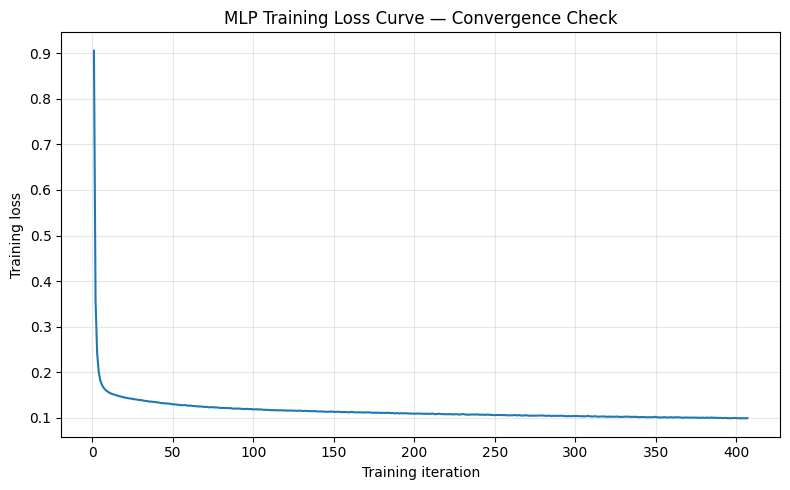

In [ ]:
# Plot the MLP training loss curve.
loss_curve = final_pipeline.named_steps["model"].loss_curve_

OUTPUT_DIR = Path("mlp_convergence_check")
OUTPUT_DIR.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(loss_curve) + 1), loss_curve)
ax.set_xlabel("Training iteration")
ax.set_ylabel("Training loss")
ax.set_title("MLP Training Loss Curve — Convergence Check")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "mlp_loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Save a separate result package; the original ten-model ZIP is not overwritten.
import joblib

convergence_df.to_csv(OUTPUT_DIR / "mlp_convergence_log.csv", index=False)
new_metrics_df.to_csv(OUTPUT_DIR / "mlp_convergence_test_metrics.csv", index=False)
comparison_df.to_csv(OUTPUT_DIR / "mlp_comparison_previous_results.csv", index=False)

with open(OUTPUT_DIR / "mlp_convergence_metadata.json", "w") as f:
    json.dump({
        "rows_after_duplicate_removal": int(len(df_clean)),
        "duplicates_removed": int(duplicate_count),
        "train_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
        "random_state": RANDOM_STATE,
        "previous_best_hyperparameters": mlp_params,
        "selected_max_iter": int(final_limit),
        "actual_iterations": int(final_pipeline.named_steps["model"].n_iter_),
        "converged_before_limit": bool(
            final_pipeline.named_steps["model"].n_iter_ < final_limit
        ),
        "sklearn_version": sklearn.__version__,
        "test_metrics": new_metrics
    }, f, indent=2, default=str)

joblib.dump(final_pipeline, OUTPUT_DIR / "mlp_convergence_checked_model.joblib")

zip_output = Path("mlp_convergence_results.zip")
with zipfile.ZipFile(zip_output, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for p in OUTPUT_DIR.rglob("*"):
        if p.is_file():
            zf.write(p, arcname=p.relative_to(OUTPUT_DIR.parent))

print("Created:", zip_output.resolve())
files.download(str(zip_output))

Created: /content/mlp_convergence_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>